In [ ]:
import kagglehub
import os

# Create a dataset folder if it does not exist
dataset_folder = '/kaggle/working/datasets'
os.makedirs(dataset_folder, exist_ok=True)

# Download the dataset
kmader_skin_cancer_mnist_ham10000_path = kagglehub.dataset_download('kmader/skin-cancer-mnist-ham10000')

# Move the downloaded files to the created dataset folder (optional)
os.rename(kmader_skin_cancer_mnist_ham10000_path, os.path.join(dataset_folder, 'skin-cancer-mnist-ham10000'))

print('Data source import complete.')


Data source import complete.


In [ ]:
# Import Libraries
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import seaborn as sns

import tensorflow as tf
from sklearn.model_selection import train_test_split
from imblearn.over_sampling import RandomOverSampler
from tensorflow.keras.utils import to_categorical

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout, BatchNormalization
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint
from tensorflow.keras.applications import DenseNet121

from sklearn.metrics import classification_report, confusion_matrix


In [ ]:

# Read Data
data_path = os.path.join(dataset_folder, 'skin-cancer-mnist-ham10000/hmnist_28_28_RGB.csv')
data = pd.read_csv(data_path)
print(data.head())


   pixel0000  pixel0001  pixel0002  pixel0003  pixel0004  pixel0005  \
0        192        153        193        195        155        192   
1         25         14         30         68         48         75   
2        192        138        153        200        145        163   
3         38         19         30         95         59         72   
4        158        113        139        194        144        174   

   pixel0006  pixel0007  pixel0008  pixel0009  ...  pixel2343  pixel2344  \
0        197        154        185        202  ...        173        124   
1        123         93        126        158  ...         60         39   
2        201        142        160        206  ...        167        129   
3        143        103        119        171  ...         44         26   
4        215        162        191        225  ...        209        166   

   pixel2345  pixel2346  pixel2347  pixel2348  pixel2349  pixel2350  \
0        138        183        147        166

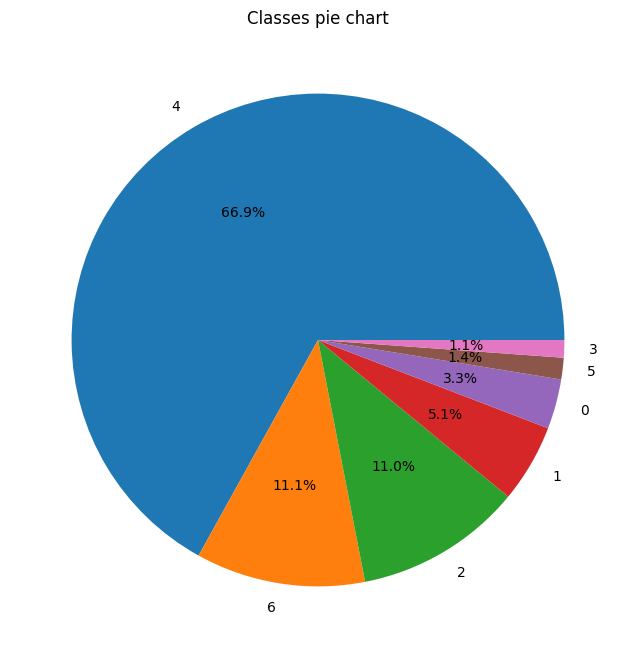

In [ ]:

# Data visualization
plt.figure(figsize=(8, 8))
plt.pie(data['label'].value_counts().values, labels=data['label'].value_counts().index, autopct='%1.1f%%')
plt.title('Classes pie chart')
plt.show()


In [ ]:

# Handle Unbalanced
# Split to features & labels
x = data.drop(columns=['label'], axis=1)
y = data['label']
ROS = RandomOverSampler(random_state=42)
x_resampled, y_resampled = ROS.fit_resample(x, y)
print(len(y_resampled))
print(x_resampled.shape)


/usr/local/lib/python3.10/dist-packages/sklearn/base.py:484: FutureWarning: `BaseEstimator._check_n_features` is deprecated in 1.6 and will be removed in 1.7. Use `sklearn.utils.validation._check_n_features` instead.
  warnings.warn(
/usr/local/lib/python3.10/dist-packages/sklearn/base.py:493: FutureWarning: `BaseEstimator._check_feature_names` is deprecated in 1.6 and will be removed in 1.7. Use `sklearn.utils.validation._check_feature_names` instead.
  warnings.warn(


46935
(46935, 2352)


In [ ]:

# Reshape image
x_resampled = np.array(x_resampled).reshape(-1, 28, 28, 3)
x_resampled = tf.image.resize(x_resampled, (32, 32))
print(x_resampled.shape)
y_resampled = to_categorical(y_resampled)
print(y_resampled.shape)


(46935, 32, 32, 3)
(46935, 7)


In [ ]:

# Split data
X = np.array(x_resampled)
Y = np.array(y_resampled)
# Split to train & test using stratify for unbalancing
x_train, x_test, y_train, y_test = train_test_split(X, Y, test_size=0.15, random_state=42)
# Split to train & val using stratify for unbalancing
x_train, x_val, y_train, y_val = train_test_split(x_train, y_train, test_size=0.15, random_state=42)

print("Train size", len(y_train))
print("Validation size", len(y_val))
print("Test size", len(y_test))


Train size 33909
Validation size 5985
Test size 7041


In [15]:
# Model Definition
model = Sequential([
    Conv2D(32, (3, 3), activation='relu', input_shape=(32, 32, 3)),
    MaxPooling2D(pool_size=(2, 2)),
    Conv2D(64, (3, 3), activation='relu'),
    MaxPooling2D(pool_size=(2, 2)),
    Conv2D(64, (3, 3), activation='relu'),
    MaxPooling2D(pool_size=(2, 2)),
    Flatten(),
    Dense(256, activation='relu'),
    Dropout(0.5),
    Dense(64, activation='relu'),
    Dense(7, activation='softmax')
])

early_stopping = EarlyStopping(monitor='val_loss', patience=8, restore_best_weights=True)
model_checkpoint = ModelCheckpoint('best_model.keras', monitor='val_loss', save_best_only=True, save_weights_only=False)
callbacks = [early_stopping, model_checkpoint]

model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
history = model.fit(x_train, y_train, validation_data=(x_val, y_val), epochs=100, batch_size=128)

# Save the best model
model.save("TheBest97.h5")


/usr/local/lib/python3.10/dist-packages/keras/src/layers/convolutional/base_conv.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 1/100
265/265 ━━━━━━━━━━━━━━━━━━━━ 52s 180ms/step - accuracy: 0.2355 - loss: 3.7270 - val_accuracy: 0.3873 - val_loss: 1.4296
Epoch 2/100
265/265 ━━━━━━━━━━━━━━━━━━━━ 48s 180ms/step - accuracy: 0.3944 - loss: 1.4367 - val_accuracy: 0.4570 - val_loss: 1.2698
Epoch 3/100
265/265 ━━━━━━━━━━━━━━━━━━━━ 84s 190ms/step - accuracy: 0.4631 - loss: 1.2836 - val_accuracy: 0.5522 - val_loss: 1.1196
Epoch 4/100
265/265 ━━━━━━━━━━━━━━━━━━━━ 52s 195ms/step - accuracy: 0.5399 - loss: 1.1372 - val_accuracy: 0.5992 - val_loss: 1.0139
Epoch 5/100
265/265 ━━━━━━━━━━━━━━━━━━━━ 78s 181ms/step - accuracy: 0.5964 - loss: 1.0277 - val_accuracy: 0.6261 - val_loss: 0.9485
Epoch 6/100
265/265 ━━━━━━━━━━━━━━━━━━━━ 82s 180ms/step - accuracy: 0.6408 - loss: 0.9277 - val_accuracy: 0.7079 - val_loss: 0.7633
Epoch 7/100
265/265 ━━━━━━━━━━━━━━━━━━━━ 47s 178ms/step - accuracy: 0.6795 - loss: 0.8219 - val_accuracy: 0.7342 - val_loss: 0.6963
Epoch 8/100
265/265 ━━━━━━━━━━━━━━━━━━━━ 82s 177ms/step - accuracy: 0.7138 -

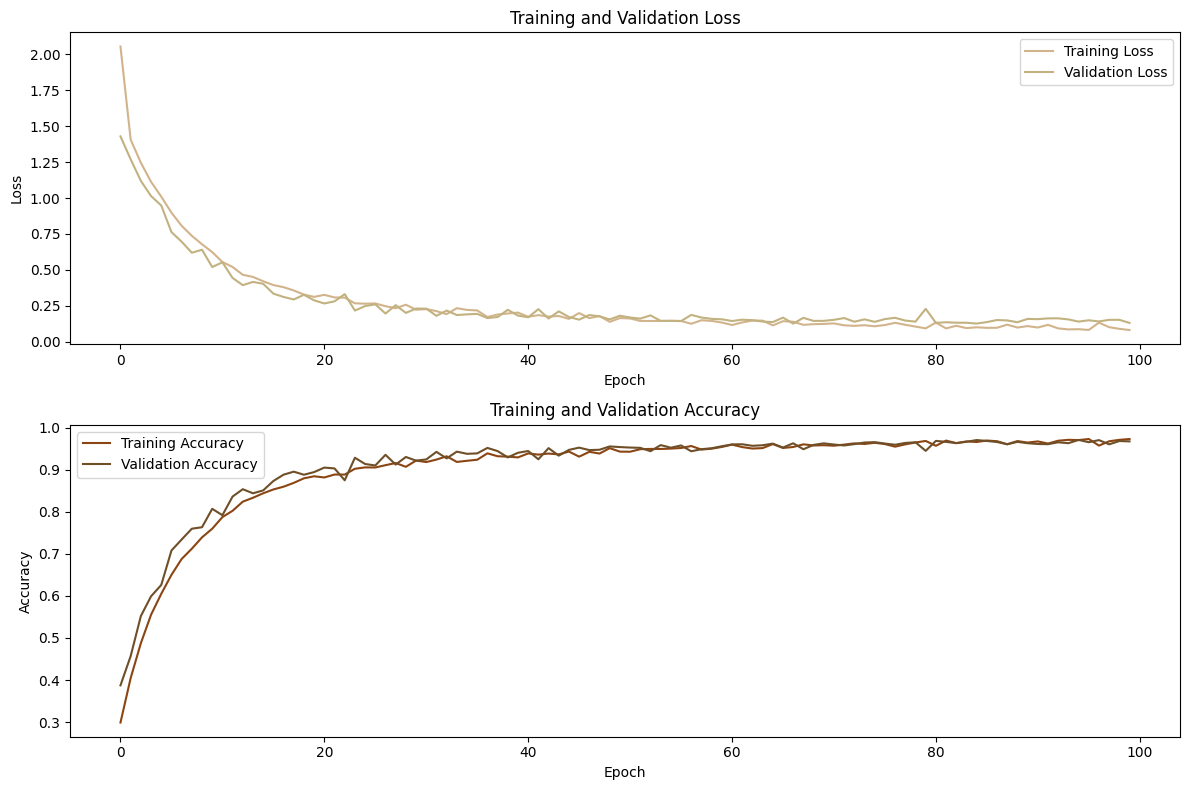

In [16]:
# Plot training results
train_loss = history.history['loss']
train_acc = history.history['accuracy']
val_loss = history.history['val_loss']
val_acc = history.history['val_accuracy']

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 8))

ax1.plot(train_loss, label='Training Loss', color='#D2B48C')
ax1.plot(val_loss, label='Validation Loss', color='#C2B280')
ax1.set_xlabel('Epoch')
ax1.set_ylabel('Loss')
ax1.set_title('Training and Validation Loss')
ax1.legend()

ax2.plot(train_acc, label='Training Accuracy', color='#8B4513')
ax2.plot(val_acc, label='Validation Accuracy', color='#6F4F28')
ax2.set_xlabel('Epoch')
ax2.set_ylabel('Accuracy')
ax2.set_title('Training and Validation Accuracy')
ax2.legend()

plt.tight_layout()
plt.show()